# 01 · Exploring the data

Before modelling, we ask a few questions about how the records were generated. Each section starts
with a **question**, answers it with code and a figure, and ends with **what we see** and **what we do
about it** in the following notebooks.

1. What data do we have, and what is missing?
2. What does the target look like?
3. How reliable are the recorded IHS4 scores?
4. Can we see flares that were never scored?
5. How do biologic treatments look in the data?
6. Are there recording artefacts or leaks to watch out for?
7. How do test_1 and test_2 differ from train?
8. Who has image and RNAseq embeddings?

In [1]:
TEAM_NAME = "skincaredivas"

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path("public")
END = pd.Timestamp("2025-12-31")          # last day of available information
SPLITS = ["train", "test_1", "test_2"]
SEED = 42
PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"]
plt.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False,
                     "legend.frameon": False, "figure.dpi": 110})
pd.set_option("display.width", 200)

def letters(axes):
    """Panel letters A, B, C… instead of titles."""
    for a, l in zip(np.ravel(axes), "ABCDEF"):
        a.text(-0.02, 1.03, l, transform=a.transAxes, fontweight="bold", fontsize=14, ha="right", va="bottom")

def load_split(split):
    dates = {"demographics": ["symptom_onset_date", "diagnosis_date"], "visits": ["visit_date"],
             "treatments": ["start_date", "end_date"], "surgeries": ["procedure_date"], "patient_assignment": []}
    t = {name: pd.read_csv(DATA / split / f"{name}.csv", parse_dates=cols) for name, cols in dates.items()}
    t["images"] = pd.read_csv(DATA / split / "images_metadata.csv", parse_dates=["capture_date"])
    t["rnaseq"] = pd.read_csv(DATA / split / "rnaseq_metadata.csv", parse_dates=["collection_date"])
    if split == "train":
        t["targets"] = pd.read_csv(DATA / split / "targets.csv")
    return t

raw = {s: load_split(s) for s in SPLITS}
y = raw["train"]["targets"].set_index("patient_id").avg_ihs4_next6

To answer the questions quickly, we first summarise each patient in one row: number of visits and of
IHS4 scores, recent scores, biologic status and antibiotic courses. This summary is for exploration
only; the model's features are built in notebook 02.

In [2]:
def patient_summary(split):
    r = raw[split]
    d = r["demographics"].set_index("patient_id")
    v = r["visits"].assign(age_d=lambda x: (END - x.visit_date).dt.days)
    s = v.dropna(subset=["ihs4_score"]).sort_values("visit_date")
    tr = r["treatments"]
    open_bio = tr[(tr.treatment_class == "Biologic") & tr.end_date.isna()].set_index("patient_id")
    ab = tr[tr.treatment_class == "Antibiotic"]
    p = pd.DataFrame(index=d.index)
    p["hurley"] = d.hurley_stage_baseline
    p["female"] = (d.sex == "Female").astype(int)
    p["ethnicity"] = d.ethnicity.fillna("Missing")
    p["age"] = END.year - d.birth_year
    p["on_bio"] = p.index.isin(open_bio.index).astype(int)
    p["years_on_line"] = (END - open_bio.start_date).dt.days / 365.25
    p["n_visits"] = v.groupby("patient_id").size()
    p["n_scored"] = s.groupby("patient_id").size()
    p["n_scored_365d"] = s[s.age_d < 365].groupby("patient_id").size()
    p["mean_score_365d"] = s[s.age_d < 365].groupby("patient_id").ihs4_score.mean()
    p["last3_mean"] = s.groupby("patient_id").tail(3).groupby("patient_id").ihs4_score.mean()
    p["days_since_last_score"] = s.groupby("patient_id").age_d.min()
    p["n_abx_365d"] = ab[(END - ab.start_date).dt.days < 365].groupby("patient_id").size()
    cnt = ["n_visits", "n_scored", "n_scored_365d", "n_abx_365d"]
    p[cnt] = p[cnt].fillna(0)
    p["score_rate"] = p.n_scored / p.n_visits.replace(0, np.nan)
    if split == "train":
        p["y"] = y.reindex(p.index)
    return p

P = {s: patient_summary(s) for s in SPLITS}

## 1. What data do we have, and what is missing?

The brief warns that records are fragmented: IHS4 is scored only at some visits, fields are missing,
and embeddings exist for few patients. We measure, for each split, the share of patients who have each
piece of information (panel A). We also show the pattern of gaps for 400 random train patients
(panel B: one column per patient, dark = present).

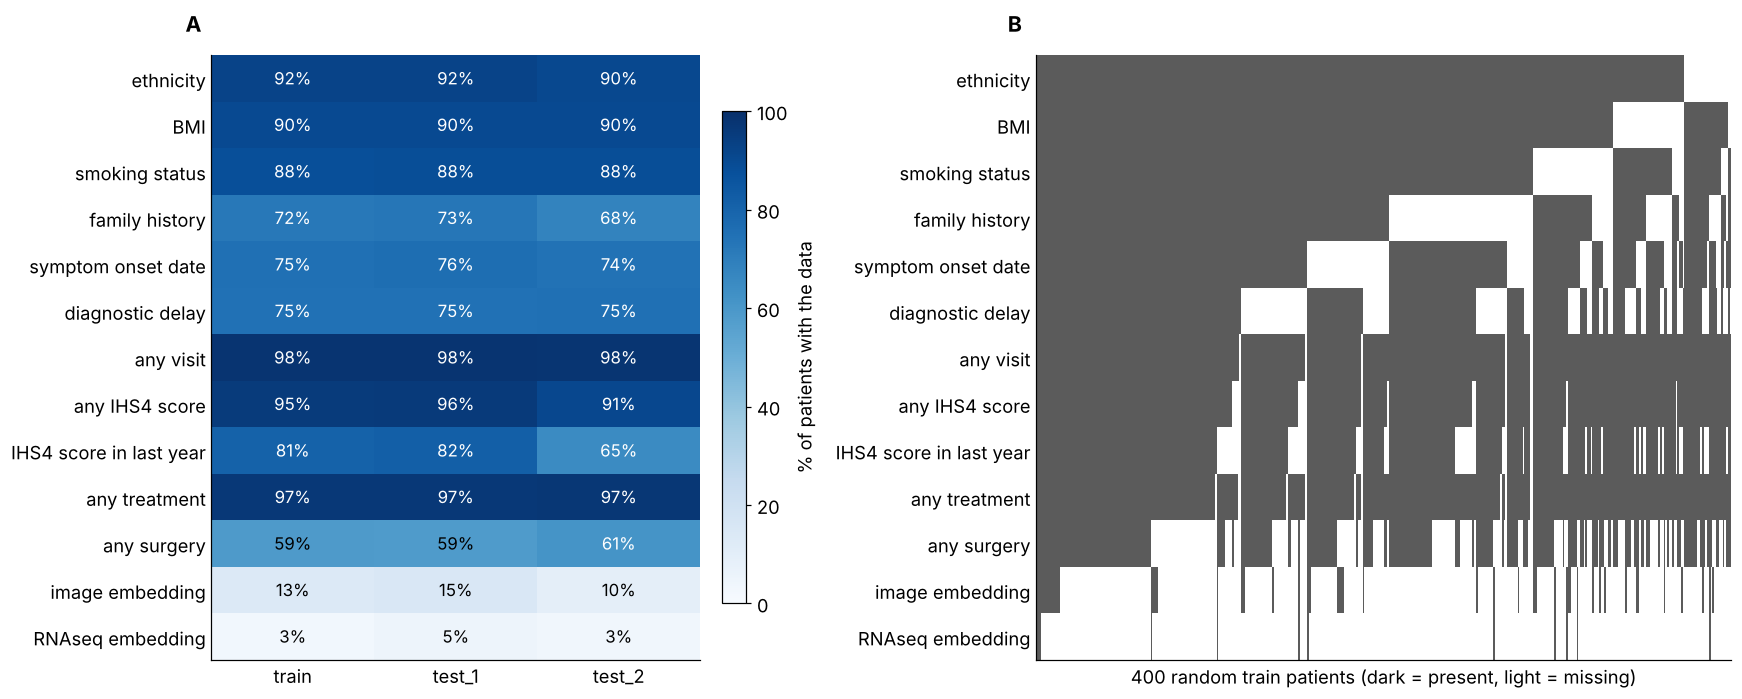

{'train': 21000, 'test_1': 4000, 'test_2': 6228} patients | {'train': 709690, 'test_1': 137285, 'test_2': 184735} visits
share of visits with an IHS4 score: {'train': np.float64(0.643), 'test_1': np.float64(0.644), 'test_2': np.float64(0.514)}


In [3]:
def availability(s):
    r, p = raw[s], P[s]
    d = r["demographics"].set_index("patient_id").reindex(p.index)
    return pd.DataFrame({
        "ethnicity": d.ethnicity.notna(),
        "BMI": d.bmi_at_baseline.notna(),
        "smoking status": d.smoking_status.notna(),
        "family history": d.family_history_hs.notna() & (d.family_history_hs != "Unknown"),
        "symptom onset date": d.symptom_onset_date.notna(),
        "diagnostic delay": d.diagnostic_delay_years.notna(),
        "any visit": p.n_visits > 0,
        "any IHS4 score": p.n_scored > 0,
        "IHS4 score in last year": p.n_scored_365d > 0,
        "any treatment": p.index.isin(r["treatments"].patient_id),
        "any surgery": p.index.isin(r["surgeries"].patient_id),
        "image embedding": p.index.isin(r["images"].patient_id),
        "RNAseq embedding": p.index.isin(r["rnaseq"].patient_id),
    }, index=p.index)

AV = {s: availability(s) for s in SPLITS}
pct = pd.DataFrame({s: 100 * AV[s].mean() for s in SPLITS})

fig, ax = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1, 1.3]})
im0 = ax[0].imshow(pct.values, cmap="Blues", vmin=0, vmax=100, aspect="auto")
ax[0].set_xticks(range(len(SPLITS)), SPLITS); ax[0].set_yticks(range(len(pct)), pct.index)
for i in range(pct.shape[0]):
    for j in range(pct.shape[1]):
        v = pct.iat[i, j]
        ax[0].text(j, i, f"{v:.0f}%", ha="center", va="center", fontsize=11, color="white" if v > 60 else "black")
ax[0].tick_params(length=0)
fig.colorbar(im0, ax=ax[0], fraction=0.046, pad=0.04, label="% of patients with the data")
sample = AV["train"].sample(400, random_state=SEED)
sample = sample.sort_values(list(sample.columns), ascending=False)
ax[1].imshow(sample.values.T.astype(int), cmap="Greys", aspect="auto", interpolation="nearest", vmin=0, vmax=1.4)
ax[1].set_yticks(range(sample.shape[1]), sample.columns); ax[1].set_xticks([]); ax[1].tick_params(length=0)
ax[1].set_xlabel("400 random train patients (dark = present, light = missing)")
letters(ax); plt.tight_layout(); plt.show()

print({s: len(P[s]) for s in SPLITS}, "patients |",
      {s: len(raw[s]["visits"]) for s in SPLITS}, "visits")
print("share of visits with an IHS4 score:", {s: round(raw[s]["visits"].ihs4_score.notna().mean(), 3) for s in SPLITS})

**What we see.** Most patients have visits (98 %) and treatment records (97 %).
* **IHS4 is the weak spot.** Only 64 % of visits carry a score, and 1 in 5 train patients has no score at
  all in the last year.
* Demographics are 88–92 % complete, except family history (~72 %) and onset date / diagnostic delay
  (~75 %).
* Embeddings are rare: 10–15 % of patients have an image, 3–5 % RNAseq.
* Panel B shows that gaps cluster: patients missing one field often miss others.
* test_2 stands out on one line: only **65 %** have a score in the last year, against 81 % in train.

**What we do.**

* Keep "missing" as information: missing categories and missing-value flags.
* Recover the diagnostic delay from the dates where possible (see Q6).
* Handle patients with few or no scores with care: a prior they can fall back on, and features that say
  how much evidence each patient has.

## 2. What does the target look like?

`avg_ihs4_next6` is the patient's true average IHS4 over January–June 2026, known only for train. We
look at its distribution (A) and at how it depends on baseline Hurley stage and biologic treatment (B).
Dashed lines mark the severity bands of the brief (mild ≤ 3, severe ≥ 11).

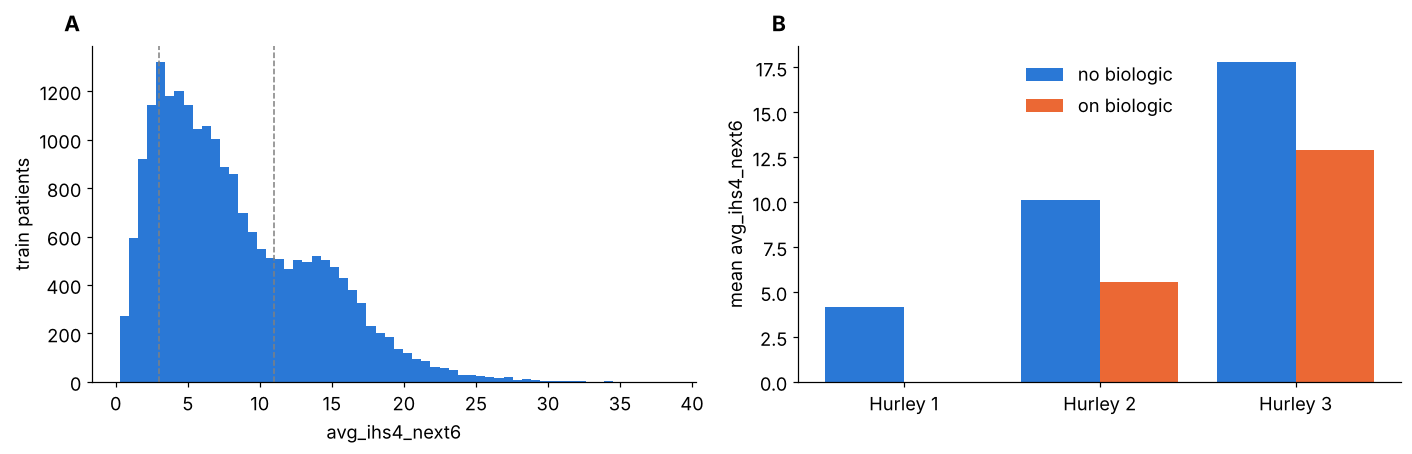

band shares: {'moderate': 0.552, 'severe': 0.288, 'mild': 0.16} | mean 8.32 | median 6.98
share on a biologic by Hurley stage: {1: 0.0, 2: 0.586, 3: 0.571}
mean target by sex: {'female': 8.51, 'male': 7.83}


In [4]:
pt = P["train"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
ax[0].hist(pt.y, bins=60, color=PAL[0])
for b in (3, 11):
    ax[0].axvline(b, color="grey", ls="--", lw=1)
ax[0].set_xlabel("avg_ihs4_next6"); ax[0].set_ylabel("train patients")
m = pt.groupby(["hurley", "on_bio"]).y.mean().unstack()
x = np.arange(3)
ax[1].bar(x - 0.2, m[0].values, 0.4, color=PAL[0], label="no biologic")
ax[1].bar(x + 0.2, m[1].reindex([1, 2, 3]).values, 0.4, color=PAL[1], label="on biologic")
ax[1].set_xticks(x, ["Hurley 1", "Hurley 2", "Hurley 3"]); ax[1].set_ylabel("mean avg_ihs4_next6"); ax[1].legend()
letters(ax); plt.tight_layout(); plt.show()

bands = pd.cut(pt.y, [-np.inf, 3, 11 - 1e-9, np.inf], labels=["mild", "moderate", "severe"]).value_counts(normalize=True)
print("band shares:", bands.round(3).to_dict(), "| mean", round(pt.y.mean(), 2), "| median", round(pt.y.median(), 2))
print("share on a biologic by Hurley stage:", pt.groupby("hurley").on_bio.mean().round(3).to_dict())
print("mean target by sex:", pt.groupby(np.where(pt.female == 1, "female", "male")).y.mean().round(2).to_dict())

**What we see.**

* The target is right-skewed: mean 8.3, median 7.0. 16 % of patients are mild, 55 % moderate and 29 %
  severe.
* **Baseline Hurley stage separates patients strongly**, and Hurley 1 patients are never on a biologic.
* Within Hurley 2 and 3, patients on a biologic are about 4–5 points lower.
* Sex shifts the mean by less than one point (women 8.5, men 7.8).

**What we do.**

* Use a loss robust to the skew (Huber), close to the MAE metric.
* Use Hurley stage × biologic status as the prior that sparsely documented patients fall back on.
* Exercise 2 only concerns Hurley 2–3 patients.

## 3. How reliable are the recorded IHS4 scores?

The target is an average over every day, but scores are only taken at visits, and patients visit
*because* they flare. We check three things on train:
* **A.** Is the recorded score biased depending on the visit type? We divide each patient's last-year
  mean score per visit type by their target; 1 means unbiased.
* **B.** How well does the recent recorded level track the target?
* **C.** How fast do old scores lose their value? We measure the error of the simplest forecast,
  "carry forward the mean of the last 3 scores", by age of the most recent score.

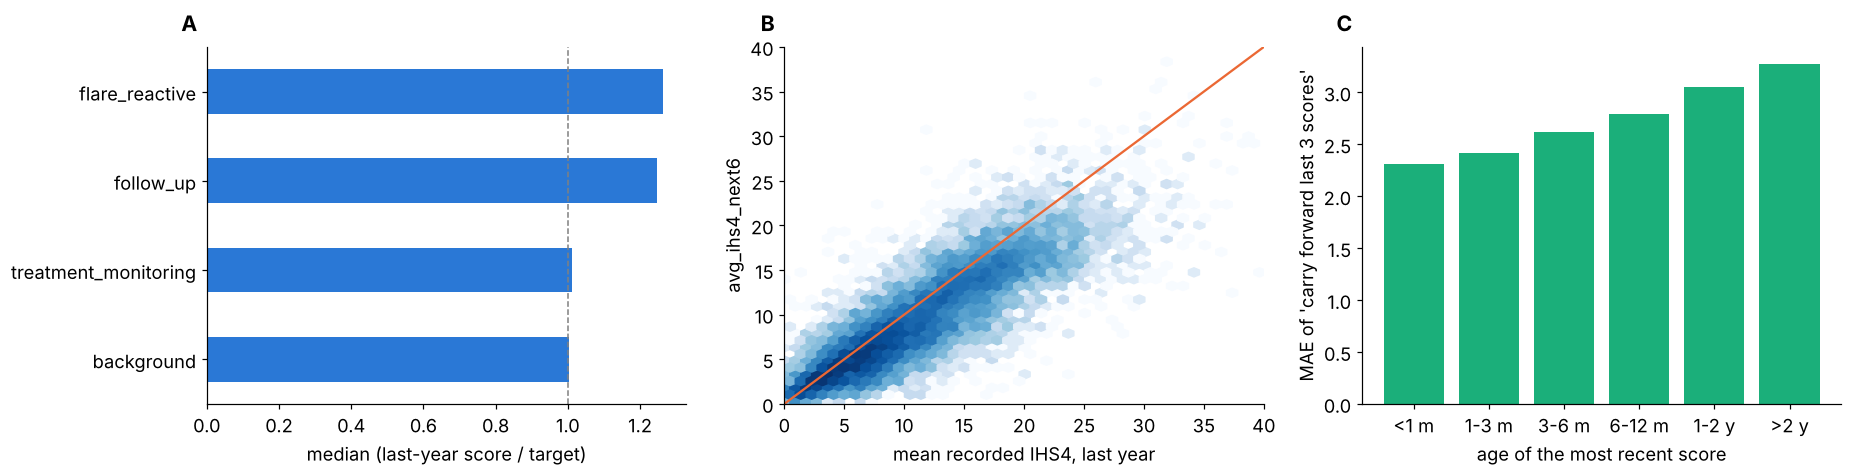

score / target by visit type: {'background': 1.0, 'flare_reactive': 1.26, 'follow_up': 1.25, 'treatment_monitoring': 1.01}
share of visits scored by type: {'background': 0.58, 'flare_reactive': 0.66, 'follow_up': 0.68, 'treatment_monitoring': 0.56}
correlation last-year mean score vs target: 0.868
carry-forward MAE by age of last score: {'<1 m': 2.31, '1-3 m': 2.42, '3-6 m': 2.62, '6-12 m': 2.8, '1-2 y': 3.05, '>2 y': 3.27}


In [5]:
v = raw["train"]["visits"].assign(age_d=lambda d: (END - d.visit_date).dt.days)
ly = v[(v.age_d < 365) & v.ihs4_score.notna()]
ratio = (ly.groupby(["visit_type", "patient_id"]).ihs4_score.mean()
         .groupby(level=0).apply(lambda s: (s / y.loc[s.index.get_level_values(1)].values).median()))
scored_share = v.groupby("visit_type").ihs4_score.apply(lambda x: x.notna().mean())
cf_err = (pt.last3_mean - pt.y).abs()
age_bin = pd.cut(pt.days_since_last_score, [-1, 30, 90, 180, 365, 730, 1e5], labels=["<1 m", "1-3 m", "3-6 m", "6-12 m", "1-2 y", ">2 y"])
e = cf_err.groupby(age_bin, observed=True).mean()

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ratio.sort_values().plot.barh(ax=ax[0], color=PAL[0]); ax[0].axvline(1, color="grey", ls="--", lw=1)
ax[0].set_xlabel("median (last-year score / target)"); ax[0].set_ylabel("")
ok = pt.mean_score_365d.notna()
ax[1].hexbin(pt.mean_score_365d[ok], pt.y[ok], gridsize=45, cmap="Blues", mincnt=1, bins="log")
ax[1].plot([0, 40], [0, 40], color=PAL[1], lw=1.5); ax[1].set_xlim(0, 40); ax[1].set_ylim(0, 40)
ax[1].set_xlabel("mean recorded IHS4, last year"); ax[1].set_ylabel("avg_ihs4_next6")
ax[2].bar(e.index.astype(str), e.values, color=PAL[2])
ax[2].set_xlabel("age of the most recent score"); ax[2].set_ylabel("MAE of 'carry forward last 3 scores'")
letters(ax); plt.tight_layout(); plt.show()

print("score / target by visit type:", ratio.round(2).to_dict())
print("share of visits scored by type:", scored_share.round(2).to_dict())
print("correlation last-year mean score vs target:", round(pt[["mean_score_365d", "y"]].corr().iloc[0, 1], 3))
print("carry-forward MAE by age of last score:", e.round(2).to_dict())

**What we see.**

* **A.** Scores from `flare_reactive` and `follow_up` visits are about **25 % above** the 6-month
  average: patients come in when they flare. Scheduled visits (`background`, `treatment_monitoring`)
  are unbiased (ratio 1.00).
* **B.** The last-year mean tracks the target well (r = 0.87), but sits above the diagonal for that
  reason.
* **C.** Old scores are poor guides. The carry-forward error rises from 2.3 (latest score under a month
  old) to 3.3 (over two years).

**What we do.**

* Divide reactive-visit scores by a visit-type factor (estimated without the target in notebook 02).
* Weight recent scores more.
* Pull patients with few or old scores toward their Hurley × biologic prior.

## 4. Can we see flares that were never scored?

The target counts flares that never reach a clinic. If they leave traces, the most likely one is an
antibiotic course. We check (i) how many courses start with no clinic visit within ±3 days, and (ii)
whether antibiotic courses predict the target, also for patients **without any IHS4 score in the last
year**, i.e. where scores cannot help.

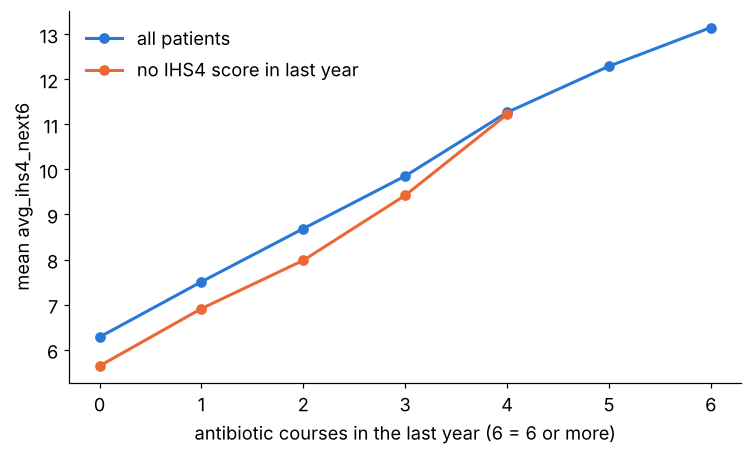

antibiotic courses with no visit within ±3 days: 29.5%
visit type next to a course: {'flare_reactive': 0.9, 'follow_up': 0.07, 'treatment_monitoring': 0.02, 'background': 0.01}


In [6]:
tr = raw["train"]["treatments"]
ab = tr[tr.treatment_class == "Antibiotic"]
near = ab[["treatment_id", "patient_id", "start_date"]].merge(raw["train"]["visits"][["patient_id", "visit_date", "visit_type"]], on="patient_id")
near = near[(near.start_date - near.visit_date).dt.days.abs() <= 3]
orphan_share = 1 - ab.treatment_id.isin(near.treatment_id).mean()

fig, ax = plt.subplots(figsize=(7, 4.3))
k = pt.n_abx_365d.clip(upper=6)
for lab_, msk, c in [("all patients", pt.index == pt.index, PAL[0]), ("no IHS4 score in last year", pt.n_scored_365d == 0, PAL[1])]:
    g = pt[msk].groupby(k[msk]).y.agg(["mean", "size"]); g = g[g["size"] >= 30]
    ax.plot(g.index, g["mean"], marker="o", color=c, lw=2, label=lab_)
ax.set_xlabel("antibiotic courses in the last year (6 = 6 or more)"); ax.set_ylabel("mean avg_ihs4_next6"); ax.legend()
plt.tight_layout(); plt.show()

print(f"antibiotic courses with no visit within ±3 days: {orphan_share:.1%}")
print("visit type next to a course:", near.drop_duplicates("treatment_id").visit_type.value_counts(normalize=True).round(2).to_dict())

**What we see.**

* **30 % of antibiotic courses have no clinic visit within ±3 days**: flares managed outside the clinic.
  When a visit is next to a course, it is a flare visit 90 % of the time.
* The target rises steadily with the number of courses in the last year, also for patients **without any
  recent IHS4 score**. Antibiotics carry severity information the scores do not.

**What we do.** Build "hidden flare" features in notebook 02:

* antibiotic counts, with out-of-clinic ("orphan") courses counted separately;
* unscored flare visits;
* incision & drainage surgeries;
* time since the last of each.

## 5. How do biologic treatments look in the data?

Exercise 2 is about patients on a biologic. We check which drugs are used at which treatment line, and
how the target changes with time on the current biologic.

current biologic: drug × line (train patients)
treatment_line     1    2    3
drug_name                     
Adalimumab      6754    1    0
Bimekizumab        5  727  167
Secukinumab        3  708  183


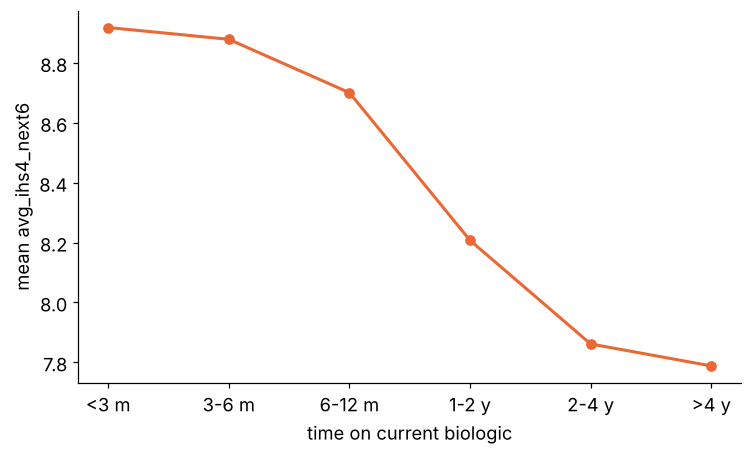

share on a biologic: {'train': np.float64(0.407), 'test_1': np.float64(0.4), 'test_2': np.float64(0.408)}


In [7]:
bio = tr[tr.treatment_class == "Biologic"]
cur = bio[bio.end_date.isna()]
print("current biologic: drug × line (train patients)")
print(pd.crosstab(cur.drug_name, cur.treatment_line.astype(int)))

pb = pt[pt.on_bio == 1]
g = pb.groupby(pd.cut(pb.years_on_line, [-0.01, 0.25, 0.5, 1, 2, 4, 10]), observed=True).y.mean()
fig, ax = plt.subplots(figsize=(7, 4.3))
ax.plot(range(len(g)), g.values, marker="o", color=PAL[1], lw=2)
ax.set_xticks(range(len(g)), ["<3 m", "3-6 m", "6-12 m", "1-2 y", "2-4 y", ">4 y"])
ax.set_xlabel("time on current biologic"); ax.set_ylabel("mean avg_ihs4_next6")
plt.tight_layout(); plt.show()
print("share on a biologic:", {s: round(P[s].on_bio.mean(), 3) for s in SPLITS})

**What we see.**

* About 40 % of patients are on a biologic in every split, as the brief says.
* **Drug and line are entangled.** Adalimumab is (almost) always first line, and secukinumab or
  bimekizumab second or third. A drug effect cannot be separated from a line effect.
* The target falls with time on the current biologic, consistent with a treatment effect that builds
  over months.

**What we do.**

* Add treatment features (on a biologic, drug, line, time on line, the patient's own response).
* In Exercise 2, report drug and line together, never one without the other.

## 6. Are there recording artefacts or leaks to watch out for?

The brief says the data contain both clinical effects and recording artefacts, and that nothing after
31 Dec 2025 may be used. We run a few targeted checks.

In [8]:
d = raw["train"]["demographics"].set_index("patient_id")
sg = raw["train"]["surgeries"].assign(age_d=lambda x: (END - x.procedure_date).dt.days)
latest = max(max(raw[s]["visits"].visit_date.max(), raw[s]["treatments"].start_date.max()) for s in SPLITS)
same_pr = (raw["train"]["visits"].merge(raw["train"]["patient_assignment"], on="patient_id", suffixes=("", "_a"))
           .eval("practitioner_id == practitioner_id_a").mean())
delay_from_dates = (d.diagnosis_date - d.symptom_onset_date).dt.days / 365.25
both = delay_from_dates.notna() & d.diagnostic_delay_years.notna()
jan16 = d.diagnosis_date < "2016-02-01"

checks = pd.Series({
    "latest date in any table": str(latest.date()),
    "visits whose practitioner = assigned practitioner": f"{same_pr:.1%}",
    "diagnostic delay = diagnosis − onset (where both known)": f"{(delay_from_dates - d.diagnostic_delay_years).abs()[both].lt(0.15).mean():.1%}",
    "delay missing but recoverable from the dates": f"{(d.diagnostic_delay_years.isna() & delay_from_dates.notna()).mean():.1%}",
    "patients 'diagnosed' in Jan 2016 (first month of data)": f"{jan16.mean():.1%} (mean target {y[jan16].mean():.1f} vs {y[~jan16].mean():.1f})",
    "patients diagnosed in 2024": int((d.diagnosis_date.dt.year == 2024).sum()),
    "surgeries in last 6 months with 6-month recurrence filled in": f"{sg[sg.age_d < 183].recurrence_within_6mo.notna().mean():.0%}",
})
checks.to_frame("result")

,result
latest date in any table,2025-12-31
visits whose practitioner = assigned practitioner,100.0%
diagnostic delay = diagnosis − onset (where both known),100.0%
delay missing but recoverable from the dates,16.8%
patients 'diagnosed' in Jan 2016 (first month of data),10.1% (mean target 9.9 vs 8.1)
patients diagnosed in 2024,15
surgeries in last 6 months with 6-month recurrence filled in,100%


**What we see.**

* No record is dated after 31 Dec 2025, and every visit's practitioner is the patient's assigned one.
* The delay field always equals diagnosis − onset when both are known, so it can be **recovered in 17 % of
  patients** where it is blank.
* **Left-censoring:** 10 % of patients are "diagnosed" in January 2016, the first month of the data.
  These are older diagnoses cut off at the start of the extract, and these patients are more severe
  (9.9 vs 8.1).
* Almost nobody is diagnosed in 2024 (15 patients), a gap in the extract rather than in the disease.
* **Leak:** `recurrence_within_6mo` is filled in even for surgeries whose 6-month window ends in 2026.
  That is information from the future.

**What we do.**

* Recompute the delay from the dates when it is blank.
* Treat "years since diagnosis" as cut off at about 10 years. The tree model can single out the
  censored group because they all share the same value.
* **Mask surgery outcomes not yet knowable** on 31 Dec 2025.

## 7. How do test_1 and test_2 differ from train?

The brief says test_1 is a random holdout and test_2 a demographically different population. We check
both claims and also look at **documentation**: how many scores each group has (panel).

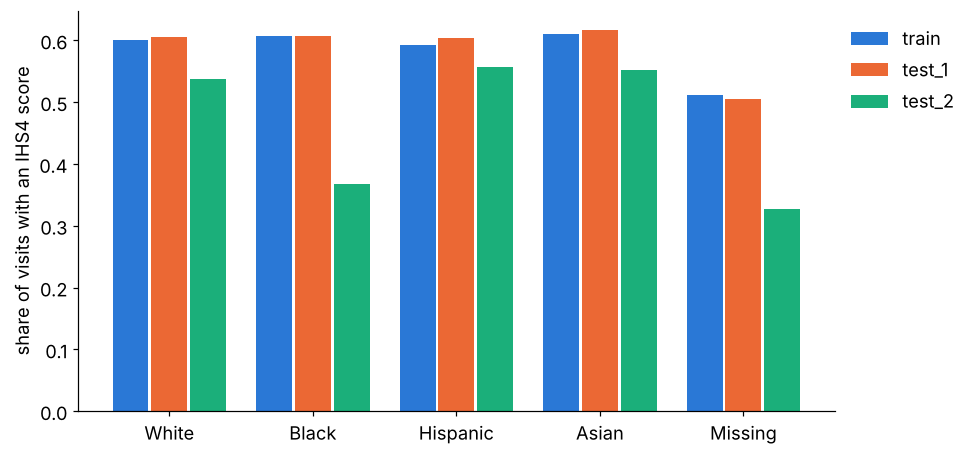

,train,test_1,test_2
female,0.720,0.726,0.893
Black/African American,0.249,0.256,0.538
age,32.980,32.704,30.762
Hurley 3,0.245,0.242,0.235
on biologic,0.407,0.400,0.408
visits per patient,33.795,34.321,29.662
share of visits scored,0.595,0.599,0.427
no IHS4 score in last year,0.194,0.183,0.351
"mean recorded IHS4, last year",10.247,10.138,10.737


In [9]:
def split_row(s):
    p = P[s]
    return pd.Series({"female": p.female.mean(), "Black/African American": (p.ethnicity == "Black/African American").mean(),
                      "age": p.age.mean(), "Hurley 3": (p.hurley == 3).mean(), "on biologic": p.on_bio.mean(),
                      "visits per patient": p.n_visits.mean(), "share of visits scored": p.score_rate.mean(),
                      "no IHS4 score in last year": (p.n_scored_365d == 0).mean(),
                      "mean recorded IHS4, last year": p.mean_score_365d.mean()})
cmp = pd.DataFrame({s: split_row(s) for s in SPLITS}).round(3)

eth = ["White", "Black/African American", "Hispanic/Latino", "Asian", "Missing"]
fig, ax = plt.subplots(figsize=(9, 4.3))
xx = np.arange(len(eth))
for i, (s, c) in enumerate(zip(SPLITS, PAL)):
    ax.bar(xx + (i - 1) * 0.27, P[s].groupby("ethnicity").score_rate.mean().reindex(eth).values, 0.25, color=c, label=s)
ax.set_xticks(xx, ["White", "Black", "Hispanic", "Asian", "Missing"]); ax.set_ylabel("share of visits with an IHS4 score")
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
plt.tight_layout(); plt.show()
cmp

**What we see.**

* test_1 matches train on every line: it is a random holdout.
* test_2 has more women (89 % vs 72 %), more Black patients (54 % vs 25 %) and younger patients, but the
  **same disease activity** (Hurley stage, biologic use, recorded IHS4).
* test_2 is also **less documented**: fewer visits, a lower scoring rate, and 35 % of patients with no
  recent score vs 19 %.
* The figure shows that the scoring drop is concentrated in **Black patients (0.61 → 0.37) and patients
  with missing ethnicity (0.51 → 0.33)**. White, Hispanic and Asian patients drop much less (about
  −0.05).

**What we do.**

* Build a **pseudo‑test_2** on train that reproduces both shifts (notebook 02, section 2), so every
  modelling choice can be checked against it.
* Explain the gap formally in notebook 02, section 6.

## 8. Who has image and RNAseq embeddings?

Embeddings exist only for subsets that were not chosen at random. Here we only look at who has them;
what they add is tested in notebook 04.

In [10]:
def emb_cov(s):
    r, p = raw[s], P[s]
    im = r["images"].merge(r["visits"][["visit_id", "visit_type", "ihs4_score"]], on="visit_id", how="left")
    rn = r["rnaseq"]
    return pd.Series({"patients with image": im.patient_id.nunique(), "patients with RNAseq": rn.patient_id.nunique(),
                      "RNAseq patients who also have an image": round(rn.patient_id.isin(im.patient_id).mean(), 2),
                      "on biologic: all / image / RNAseq": f"{p.on_bio.mean():.2f} / {p.loc[im.patient_id, 'on_bio'].mean():.2f} / {p.loc[rn.patient_id, 'on_bio'].mean():.2f}",
                      "image taken at a flare_reactive visit": round((im.visit_type == "flare_reactive").mean(), 2),
                      "image visit was scored": round(im.ihs4_score.notna().mean(), 2)})
pd.DataFrame({s: emb_cov(s) for s in SPLITS})

,train,test_1,test_2
patients with image,2800,600,600
patients with RNAseq,600,200,200
RNAseq patients who also have an image,1.0,1.0,1.0
on biologic: all / image / RNAseq,0.41 / 0.70 / 1.00,0.40 / 0.70 / 1.00,0.41 / 0.70 / 1.00
image taken at a flare_reactive visit,1.0,1.0,1.0
image visit was scored,0.66,0.66,0.5


**What we see.**

* Images come only from flare visits, and a third of those visits were never scored (half in test_2).
* 70 % of image patients and all RNAseq patients are on a biologic, against 41 % overall.
* Every RNAseq patient also has an image.

**What we do.**

* Use the embeddings as corrections to the clinical forecast, evaluated on the same patients.
* Limit every claim to these subsets (notebook 04).

## Summary: from questions to modelling decisions

| Question | Finding | Decision |
| --- | --- | --- |
| 1. What is missing? | Only 64 % of visits are scored; gaps cluster; embeddings are rare | Missingness as information; priors for sparse patients |
| 2. Target | Skewed; Hurley and biologic status shift it strongly | Robust loss; Hurley × biologic prior |
| 3. Recorded IHS4 | Reactive-visit scores ~25 % too high; old scores lose value | Visit-type correction; recency weighting; shrinkage |
| 4. Hidden flares | 30 % of antibiotics outside the clinic; they predict the target | Antibiotic and flare-trace features |
| 5. Biologics | Drug and line entangled; target falls with time on treatment | Treatment features; never interpret drug apart from line |
| 6. Artefacts | Censored 2016 diagnoses, 2024 gap, surgery outcomes from the future | Recover the delay; mask future fields |
| 7. Test sets | test_1 = train; test_2 = new population + targeted under-documentation | Pseudo‑test_2 for validation and gap analysis |
| 8. Embeddings | Small, non-random subsets | Corrections on top of the clinical model, same-patient comparisons |